# AE 598 Homework 2: Tabular Methods

# Connor Gordon

## **NetID:** cpg5

# Import Necessary Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pprint import pprint
from collections import defaultdict

## Import Gymnasium environment

In [2]:
!pip install gymnasium==0.29.1 gymnasium[toy-text] pygame==2.5.2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 953.9/953.9 kB 9.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.9/13.9 MB 71.7 MB/s eta 0:00:00
  Attempting uninstall: pygame
    Found existing installation: pygame 2.6.1
    Uninstalling pygame-2.6.1:
      Successfully uninstalled pygame-2.6.1
  Attempting uninstall: gymnasium
    Found existing installation: gymnasium 1.2.1
    Uninstalling gymnasium-1.2.1:
      Successfully uninstalled gymnasium-1.2.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gymnasium>=1.0.0, but you have gymnasium 0.29.1 which is incompatible.


## Navigate to Frozen Lake Environment

In [3]:
import gymnasium as gym

# Check available toy-text environments
envs = [env_id for env_id in gym.envs.registry.keys() if "FrozenLake" in env_id]
print(envs)

['FrozenLake-v1', 'FrozenLake8x8-v1']


In [4]:
env = gym.make("FrozenLake-v1", render_mode="ansi", is_slippery=False)

# First, fully define MDP

Because we are learning the *Gymnasium* Environment, the Frozen Lake MDP is already fully defined for us within the environment.

## Write a function that defines the MDP and outputs the necessary parameters

In [5]:
def define_mdp(chosen_env = 'FrozenLake-v1', is_slippery=True):


  # Initialize environment
  env = gym.make(chosen_env, is_slippery = is_slippery)


  # Define state and action spaces
  n_states = env.observation_space.n
  n_actions = env.action_space.n


  # Collect transition and reward data
  # Transition matrix
  P = env.unwrapped.P

  # Rewards for each action
  R = {s: {a: [] for a in range(n_actions)} for s in range(n_states)}


  # Create dictionary to store reward data
  for s in range(n_states):
      for a in range(n_actions):
          transitions = P[s][a]
          for (prob, next_state, reward, done) in transitions:
              R[s][a].append(reward)


  # Create dictionary of necessary parameters for MDP
  mdp = {
      "S": list(range(n_states)),
      "A": list(range(n_actions)),
      "P": P,
      "R": R,
      "env": env,
  }

  return mdp

## Extract Necessary Parameters for `is_slippery=False`

In [6]:
mdp_noslip = define_mdp("FrozenLake-v1", is_slippery=False)

S, A, P, R, env_noslip = mdp_noslip["S"], mdp_noslip["A"], mdp_noslip["P"], mdp_noslip["R"], mdp_noslip["env"]

print(f"Number of States: {len(S)}")
print(f"Number of Actions: {len(A)}")
print("Sample of Transition Matrix:")
pprint(P[0])
print(f"Sample of Reward Matrix:")
pprint(R[0])

Number of States: 16
Number of Actions: 4
Sample of Transition Matrix:
{0: [(1.0, 0, 0.0, False)],
 1: [(1.0, 4, 0.0, False)],
 2: [(1.0, 1, 0.0, False)],
 3: [(1.0, 0, 0.0, False)]}
Sample of Reward Matrix:
{0: [0.0], 1: [0.0], 2: [0.0], 3: [0.0]}


## Extract Necessary Parameters for `is_slippery=True`

In [7]:
mdp_slippery = define_mdp("FrozenLake-v1", is_slippery=True)

S, A, P, R, env_slippery = mdp_slippery["S"], mdp_slippery["A"], mdp_slippery["P"], mdp_slippery["R"], mdp_slippery["env"]

print(f"Number of States: {len(S)}")
print(f"Number of Actions: {len(A)}")
print("Sample of Transition Matrix:")
pprint(P[0])
print(f"Sample of Reward Matrix:")
pprint(R[0])

Number of States: 16
Number of Actions: 4
Sample of Transition Matrix:
{0: [(0.3333333333333333, 0, 0.0, False),
     (0.3333333333333333, 0, 0.0, False),
     (0.3333333333333333, 4, 0.0, False)],
 1: [(0.3333333333333333, 0, 0.0, False),
     (0.3333333333333333, 4, 0.0, False),
     (0.3333333333333333, 1, 0.0, False)],
 2: [(0.3333333333333333, 4, 0.0, False),
     (0.3333333333333333, 1, 0.0, False),
     (0.3333333333333333, 0, 0.0, False)],
 3: [(0.3333333333333333, 1, 0.0, False),
     (0.3333333333333333, 0, 0.0, False),
     (0.3333333333333333, 0, 0.0, False)]}
Sample of Reward Matrix:
{0: [0.0, 0.0, 0.0], 1: [0.0, 0.0, 0.0], 2: [0.0, 0.0, 0.0], 3: [0.0, 0.0, 0.0]}


# Define Helpful Functions Necessary

## Define a function to use to select the greedy policy while exploring with probability $\epsilon$

In [8]:
def epsilon_greedy(state, Q, epsilon):
  num_actions = env.action_space.n

  if np.random.rand() < epsilon:
    action = np.random.randint(num_actions)
  else:
    action = np.argmax(Q[state])

  return action

## Define a function to evaluate policy by extracting the greedy policy after a certain number of time steps (Albrecht et al. 2.7)

In [9]:
def evaluate_policy(env, Q, num_eval_episodes):

  # Initialize total reward
  total_reward = 0

  # Perform 100 episodes to get total reward
  for _ in range(num_eval_episodes):
    s, _ = env.reset()
    done = False

    while not done:
      a = np.argmax(Q[s]) # Greedy policy
      s, r, terminated, truncated, _ = env.step(a)
      done = terminated or truncated
      total_reward += r


  # Return average reward
  return total_reward / num_eval_episodes

# On-Policy First-Visit Monte Carlo Control

## Define a function to find the optimal policy using pseudocode in Sutton & Barto 5.4

In [10]:
def mc_control(env, gamma=0.95, epsilon=0.3, max_episodes=20000, evaluation_step=2000, num_eval_episodes=20, epsilon_decay=True):

  # Initialize epsilon for epsilon decay
  epsilon0 = epsilon

  # Initialize action-value function, returns, and policy
  # Use defaultdict to easily add "future states"

  # Action-value function
  Q = defaultdict(lambda: np.zeros(env.action_space.n))

  # Returns as an "empty list"
  Returns = defaultdict(list)

  # Policy (pi), using an arbitrary epsilon-soft policy (1/|A|)
  policy = defaultdict(lambda: np.ones(env.action_space.n) / env.action_space.n)

  # Create empty lists to track evaluation returns and time steps
  evaluation_returns = []
  time_steps = []
  total_steps = 0

  # Track episode length and episode return as well
  episode_lengths = []
  episode_rewards = []


  # Repeat forever
  for episode in range(1, max_episodes + 1):

    # Generate an episode following pi
    episode_data = [] # Empty list to store episode data
    s, _ = env.reset() # Reset environment
    done = False

    # Track steps in episode and total_reward per episode
    total_reward = 0
    episode_steps = 0

    while not done:

      # Add epsilon decay if desired
      if epsilon_decay == True:
        epsilon = max(0.05, epsilon0 - 5 * total_steps * 10**-7)

      # Select random action based on current policy
      a = np.random.choice(env.action_space.n, p = policy[s])

      # Generate next state based on action
      next_s, r, terminated, truncated, _ = env.step(a)

      # Continue until epsiode ends (i.e. agent falls in hole or reaches goal)
      done = terminated or truncated

      # Update total steps
      total_steps += 1

      # Append episode data
      episode_data.append((s, a, r))

      # Continue looping until episode ends
      s = next_s


      # Periodically compute evaluation returns
      if total_steps % evaluation_step == 0:
        # Compute average evaluation return
        avg_eval_r = evaluate_policy(env, Q, num_eval_episodes)

        # Append empty lists
        evaluation_returns.append(avg_eval_r)
        time_steps.append(total_steps)


      # Track episode length and return as well
      episode_steps += 1
      episode_lengths.append(episode_steps)
      total_reward += r
      episode_rewards.append(total_reward)


    # Apply Monte Carlo Updates

    # Initialize g
    G = 0

    # Keep track of visited states
    visited = set()


    # Loop through episode data from T-1, T-2, ... , 0
    for t in reversed(range(len(episode_data))):

      # Extract data from time step
      s_t, a_t, r_t = episode_data[t]

      # Update G
      G = gamma * G + r_t


      # Check if state has been visited
      if (s_t, a_t) not in visited:
        visited.add((s_t, a_t))

        # Find previous action-value (to check convergence)
        prev_Q = Q[s_t][a_t]

        # Average and update returns
        Returns[(s_t, a_t)].append(G)
        Q[s_t][a_t] = np.mean(Returns[(s_t, a_t)])

        # Update A*
        A_star = np.argmax(Q[s_t])


        # Use epsilon-soft to improve policy
        for action in range(env.action_space.n):
          if action == A_star:
            policy[s_t][action] = 1 - epsilon + (epsilon / env.action_space.n)
          else:
            policy[s_t][action] = epsilon / env.action_space.n

    # Extract final greedy policy
    greedy_policy = {state: np.argmax(Q[state]) for state in Q}

  return Q, greedy_policy, evaluation_returns, time_steps, episode_lengths, episode_rewards

# SARSA

## Define a function to find the optimal policy using pseudocode in Sutton & Barto 6.4

In [11]:
def SARSA(env, alpha=0.5, gamma=0.95, epsilon=0.3, max_episodes=20000, evaluation_step=2000, num_eval_episodes=20, epsilon_decay=True):

  # Initialize epsilon for epsilon decay
  epsilon0 = epsilon

  # Initialize action-value function
  # Use defaultdict to easily add "future states"

  # Action-value function
  Q = defaultdict(lambda: np.zeros(env.action_space.n))

  # Create empty lists to track evaluation returns and time steps
  evaluation_returns = []
  time_steps = []
  total_steps = 0

  # Track episode length and episode return as well
  episode_lengths = []
  episode_rewards = []

  # Repeat forever
  for episode in range(1, max_episodes + 1):

    # Initialize state
    s, _ = env.reset() # Reset environment
    done = False

    # Choose intitial action using epsilon-greedy policy
    a = epsilon_greedy(s, Q, epsilon)

    # Track steps in episode and total_reward per episode
    total_reward = 0
    episode_steps = 0


    while not done:

      # Add epsilon decay if desired
      if epsilon_decay == True:
        epsilon = max(0.05, epsilon0 - 5 * total_steps * 10**-7)

      # Generate next state based on action
      next_s, r, terminated, truncated, _ = env.step(a)

      # Continue until epsiode ends (i.e. agent falls in hole or reaches goal)
      done = terminated or truncated

      # Update time steps
      total_steps += 1

      # Choose next action from epsilon-greedy policy derived from Q
      next_a = epsilon_greedy(next_s, Q, epsilon)

      # Find previous action-value (to check convergence)
      prev_Q = Q[s][a]


      # SARSA Update
      # Separate into TD target and error for readability
      # Do not bootstrap terminal states
      if done:
        td_target = r
      else:
        td_target = r + gamma * Q[next_s][next_a]
      td_error = td_target - Q[s][a]

      # Update Q
      Q[s][a] += alpha * td_error

      # Re-intialize loop with next state-action pair
      s, a = next_s, next_a

      # Periodically compute evaluation returns
      if total_steps % evaluation_step == 0:
        # Compute average evaluation return
        avg_eval_r = evaluate_policy(env, Q, num_eval_episodes)

        # Append empty lists
        evaluation_returns.append(avg_eval_r)
        time_steps.append(total_steps)

      # Track episode length and return as well
      episode_steps += 1
      episode_lengths.append(episode_steps)
      total_reward += r
      episode_rewards.append(total_reward)


  # Derive final policy from Q using epsilon greedy
  policy = {state: np.argmax(Q[state]) for state in Q}

  return Q, policy, evaluation_returns, time_steps, episode_lengths, episode_rewards

# Q-Learning

## Define a function to find the optimal policy using pseudocode in Sutton & Barto 6.5

In [12]:
def Q_learning(env, alpha=0.5, gamma=0.95, epsilon=0.3, max_episodes=20000, evaluation_step=2000, num_eval_episodes=20, epsilon_decay=True):

  # Initialize epsilon for epsilon decay
  epsilon0 = epsilon

  # Initialize action-value function and policy
  # Use defaultdict to easily add "future states"

  # Action-value function
  Q = defaultdict(lambda: np.zeros(env.action_space.n))

  # Create empty lists to track evaluation returns and time steps
  evaluation_returns = []
  time_steps = []
  total_steps = 0

  # Track episode length and episode return as well
  episode_lengths = []
  episode_rewards = []


  # Repeat forever
  for episode in range(1, max_episodes + 1):

    # Initialize state
    s, _ = env.reset() # Reset environment
    done = False

    # Track steps in episode and total_reward per episode
    total_reward = 0
    episode_steps = 0


    while not done:

      # Add epsilon decay if desired
      if epsilon_decay == True:
        epsilon = max(0.05, epsilon0 - 5 * total_steps * 10**-7)

      # Choose action from s using epsilon-greedy policy
      a = epsilon_greedy(s, Q, epsilon)

      # Generate next state based on action
      next_s, r, terminated, truncated, _ = env.step(a)

      # Continue until epsiode ends (i.e. agent falls in hole or reaches goal)
      done = terminated or truncated

      # Update total steps
      total_steps += 1

      # Find previous action-value (to check convergence)
      prev_Q = Q[s][a]


      # Q-Learning Update
      # Separate into TD target and error for readability
      # Do not bootstrap terminal states
      if done:
        td_target = r
      else:
        td_target = r + gamma * np.max(Q[next_s])
      td_error = td_target - Q[s][a]

      # Update Q
      Q[s][a] += alpha * td_error


      # Re-intialize loop with next state
      s = next_s

      # Periodically compute evaluation returns
      if total_steps % evaluation_step == 0:
        # Compute average evaluation return
        avg_eval_r = evaluate_policy(env, Q, num_eval_episodes)

        # Append empty lists
        evaluation_returns.append(avg_eval_r)
        time_steps.append(total_steps)

      # Track episode length and return as well
      episode_steps += 1
      episode_lengths.append(episode_steps)
      total_reward += r
      episode_rewards.append(total_reward)

  # Derive final policy from Q using epsilon greedy
  policy = {state: np.argmax(Q[state]) for state in Q}

  return Q, policy, evaluation_returns, time_steps, episode_lengths, episode_rewards

# Run Each Algorithm

## First, No Epsilon Decay

### Non-Slippery Condition

In [13]:
# Define environment using previously defined MDP
env_noslip = mdp_noslip["env"]

# Run each algorithm
print("Evaluating Monte Carlo...")
mc_noslip = mc_control(env_noslip)
print("Evaluating SARSA...")
sarsa_noslip = SARSA(env_noslip, epsilon_decay=False)
print("Evaluating Q-Learning...")
q_learning_noslip = Q_learning(env_noslip, epsilon_decay=False)

Evaluating Monte Carlo...
Evaluating SARSA...
Evaluating Q-Learning...


### Slippery Condition

In [14]:
# Define environment using previously defined MDP
env_slippery = mdp_slippery["env"]

# Run each algorithm
print("Evaluating Monte Carlo...")
mc_slippery = mc_control(env_slippery)
print("Evaluating SARSA...")
sarsa_slippery = SARSA(env_slippery, epsilon_decay=False)
print("Evaluating Q-Learning...")
q_learning_slippery = Q_learning(env_slippery, epsilon_decay=False)

Evaluating Monte Carlo...
Evaluating SARSA...
Evaluating Q-Learning...


## Now, with Epsilon Decay

### Non-Slippery Condition

In [48]:
# Define environment using previously defined MDP
env_noslip = mdp_noslip["env"]

# Run each algorithm
print("Evaluating Monte Carlo...")
mc_noslip_decay = mc_control(env_noslip, epsilon_decay=True)
print("Evaluating SARSA...")
sarsa_noslip_decay = SARSA(env_noslip, epsilon_decay=True)
print("Evaluating Q-Learning...")
q_learning_noslip_decay = Q_learning(env_noslip, epsilon_decay=True)

Evaluating Monte Carlo...
Evaluating SARSA...
Evaluating Q-Learning...


### Slippery Condition

In [16]:
# Define environment using previously defined MDP
env_slippery = mdp_slippery["env"]

# Run each algorithm
print("Evaluating Monte Carlo...")
mc_slippery_decay = mc_control(env_slippery, epsilon_decay=True)
print("Evaluating SARSA...")
sarsa_slippery_decay = SARSA(env_slippery, epsilon_decay=True)
print("Evaluating Q-Learning...")
q_learning_slippery_decay = Q_learning(env_slippery, epsilon_decay=True)

Evaluating Monte Carlo...
Evaluating SARSA...
Evaluating Q-Learning...


## Now, with lower $\alpha$

### Non-Slippery Condition

In [18]:
# Define environment using previously defined MDP
env_noslip = mdp_noslip["env"]

# Run each algorithm
print("Evaluating SARSA...")
sarsa_noslip_la = SARSA(env_noslip, alpha=0.2, epsilon_decay=False)
print("Evaluating Q-Learning...")
q_learning_noslip_la = Q_learning(env_noslip, alpha=0.2, epsilon_decay=False)

Evaluating SARSA...
Evaluating Q-Learning...


### Slippery Condition

In [19]:
# Define environment using previously defined MDP
env_slippery = mdp_slippery["env"]

# Run each algorithm
print("Evaluating SARSA...")
sarsa_slippery_la = SARSA(env_slippery, alpha=0.2, epsilon_decay=False)
print("Evaluating Q-Learning...")
q_learning_slippery_la = Q_learning(env_slippery, alpha=0.2, epsilon_decay=False)

Evaluating SARSA...
Evaluating Q-Learning...


# Plot Evaluation Returns vs. Number of Time Steps

## Non-Slippery Condition

### First, with No Epsilon Decay

Extract necessary arrays from returns

In [20]:
# Monte Carlo
mc_eval_returns = mc_noslip[2]
mc_time_steps = mc_noslip[3]

# SARSA
sarsa_eval_returns = sarsa_noslip[2]
sarsa_time_steps = sarsa_noslip[3]

# Q-Learning
ql_eval_returns = q_learning_noslip[2]
ql_time_steps = q_learning_noslip[3]

Create Plot:

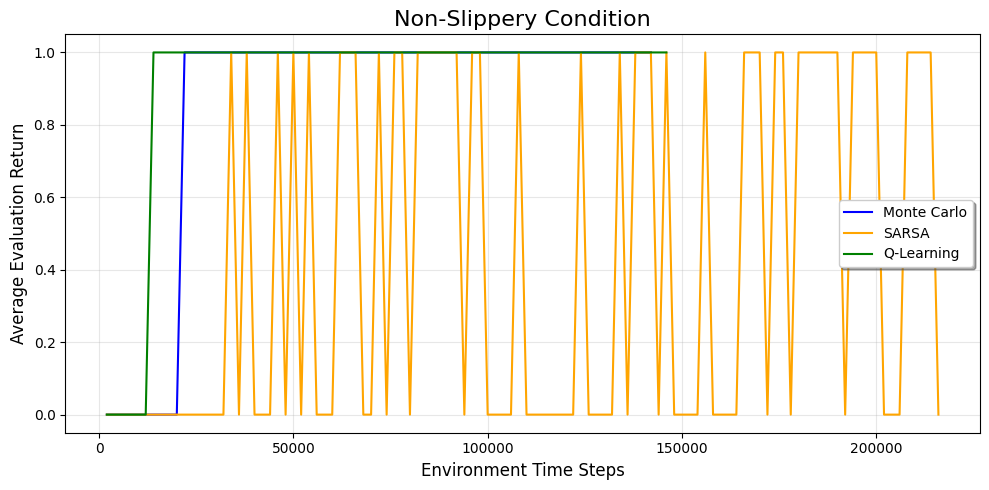

In [71]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))

ax.plot(mc_time_steps, mc_eval_returns, label='Monte Carlo', color='blue')
ax.plot(sarsa_time_steps, sarsa_eval_returns, label='SARSA', color='orange')
ax.plot(ql_time_steps, ql_eval_returns, label='Q-Learning', color='green')

ax.set_title("Non-Slippery Condition", fontsize=16)
ax.set_xlabel("Environment Time Steps", fontsize=12)
ax.set_ylabel("Average Evaluation Return", fontsize=12)
ax.legend(shadow=True, fancybox=True)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Now, with Epsilon Decay

Extract necessary arrays from returns

In [49]:
# Monte Carlo
mc_eval_returns_decay = mc_noslip_decay[2]
mc_time_steps_decay = mc_noslip_decay[3]

# SARSA
sarsa_eval_returns_decay = sarsa_noslip_decay[2]
sarsa_time_steps_decay = sarsa_noslip_decay[3]

# Q-Learning
ql_eval_returns_decay = q_learning_noslip_decay[2]
ql_time_steps_decay = q_learning_noslip_decay[3]

Create Plot:

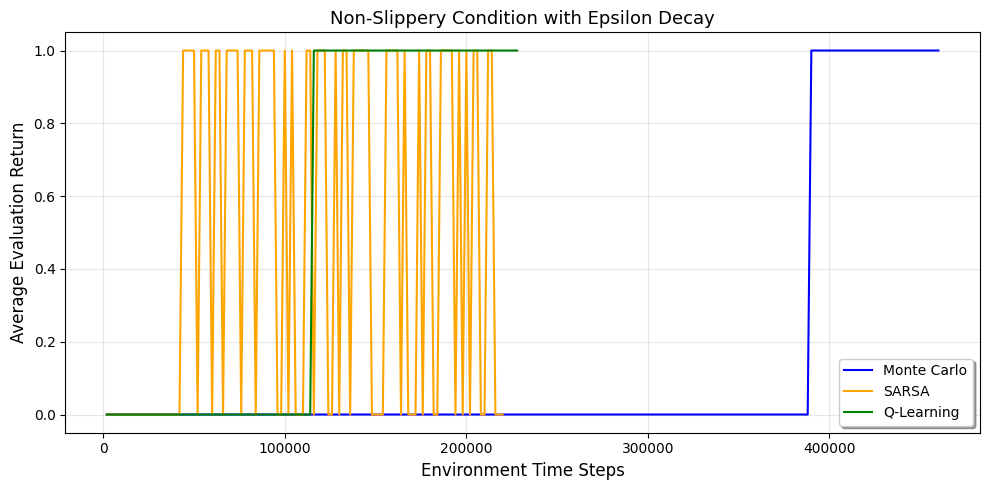

In [54]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))

ax.plot(mc_time_steps_decay, mc_eval_returns_decay, label='Monte Carlo', color='blue')
ax.plot(sarsa_time_steps_decay, sarsa_eval_returns_decay, label='SARSA', color='orange')
ax.plot(ql_time_steps_decay, ql_eval_returns_decay, label='Q-Learning', color='green')

ax.set_title("Non-Slippery Condition with Epsilon Decay", fontsize=14)
ax.set_xlabel("Environment Time Steps", fontsize=12)
ax.set_ylabel("Average Evaluation Return", fontsize=12)
ax.legend(shadow=True, fancybox=True)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Now, with low $\alpha$

Extract necessary arrays from returns

In [24]:
# SARSA
sarsa_eval_returns_la = sarsa_noslip_la[2]
sarsa_time_steps_la = sarsa_noslip_la[3]

# Q-Learning
ql_eval_returns_la = q_learning_noslip_la[2]
ql_time_steps_la = q_learning_noslip_la[3]

Create Plot:

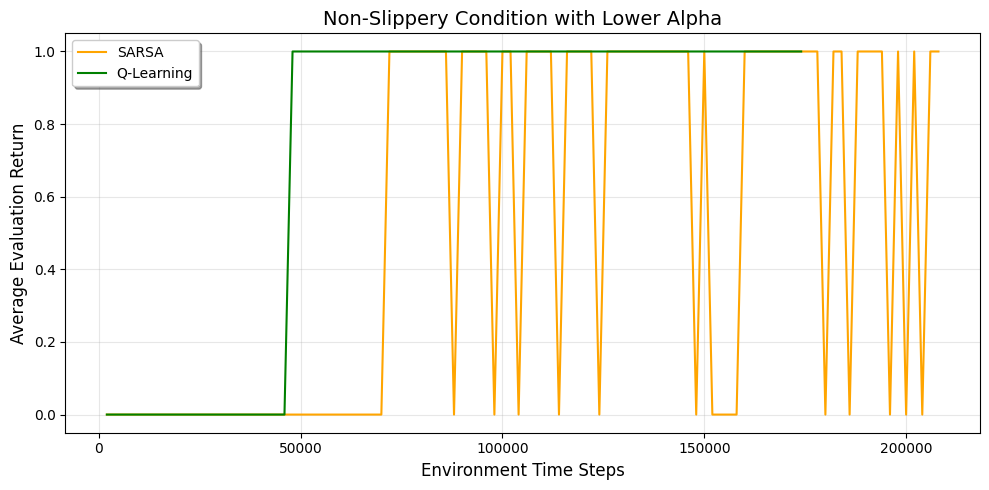

In [55]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))

ax.plot(sarsa_time_steps_la, sarsa_eval_returns_la, label='SARSA', color='orange')
ax.plot(ql_time_steps_la, ql_eval_returns_la, label='Q-Learning', color='green')

ax.set_title("Non-Slippery Condition with Lower Alpha", fontsize=14)
ax.set_xlabel("Environment Time Steps", fontsize=12)
ax.set_ylabel("Average Evaluation Return", fontsize=12)
ax.legend(shadow=True, fancybox=True)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Slippery Condition

### First, with No Epsilon Decay

Extract necessary arrays from returns

In [26]:
# Monte Carlo
mc_eval_returns_slippery = mc_slippery[2]
mc_time_steps_slippery = mc_slippery[3]

# SARSA
sarsa_eval_returns_slippery = sarsa_slippery[2]
sarsa_time_steps_slippery = sarsa_slippery[3]

# Q-Learning
ql_eval_returns_slippery = q_learning_slippery[2]
ql_time_steps_slippery = q_learning_slippery[3]

Create Plot:

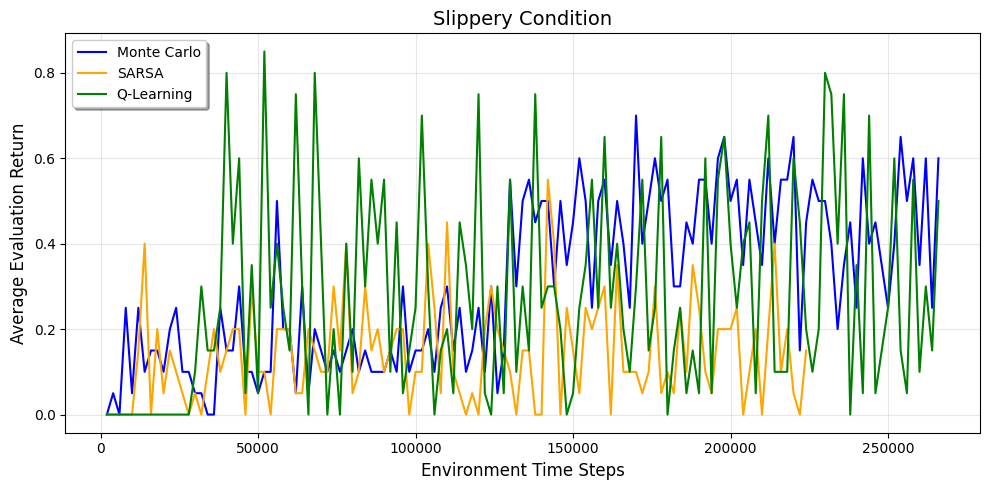

In [56]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))

ax.plot(mc_time_steps_slippery, mc_eval_returns_slippery, label='Monte Carlo', color='blue')
ax.plot(sarsa_time_steps_slippery, sarsa_eval_returns_slippery, label='SARSA', color='orange')
ax.plot(ql_time_steps_slippery, ql_eval_returns_slippery, label='Q-Learning', color='green')

ax.set_title("Slippery Condition", fontsize=14)
ax.set_xlabel("Environment Time Steps", fontsize=12)
ax.set_ylabel("Average Evaluation Return", fontsize=12)
ax.legend(shadow=True, fancybox=True)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Now, with Epsilon Decay

Extract necessary arrays from returns

In [28]:
# Monte Carlo
mc_eval_returns_slippery_decay = mc_slippery_decay[2]
mc_time_steps_slippery_decay = mc_slippery_decay[3]

# SARSA
sarsa_eval_returns_slippery_decay = sarsa_slippery_decay[2]
sarsa_time_steps_slippery_decay = sarsa_slippery_decay[3]

# Q-Learning
ql_eval_returns_slippery_decay = q_learning_slippery_decay[2]
ql_time_steps_slippery_decay = q_learning_slippery_decay[3]

Create Plot:

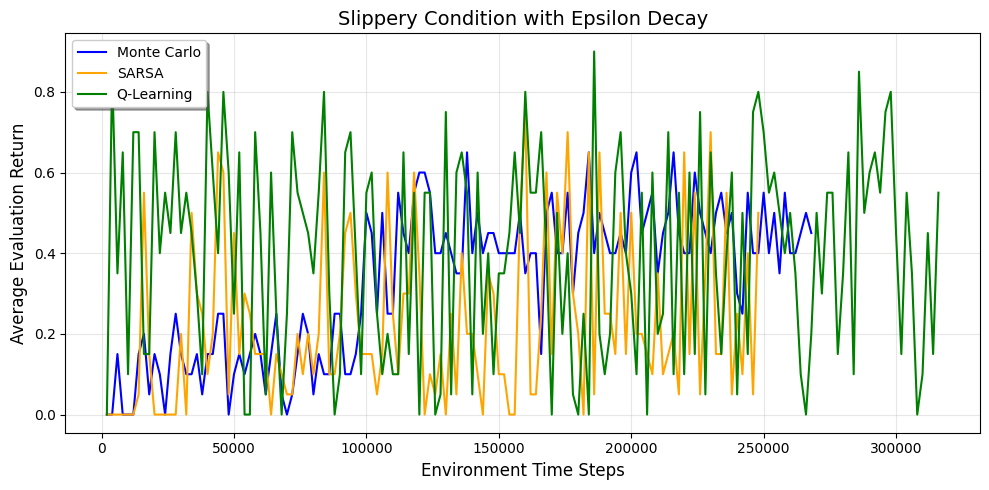

In [57]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))

ax.plot(mc_time_steps_slippery_decay, mc_eval_returns_slippery_decay, label='Monte Carlo', color='blue')
ax.plot(sarsa_time_steps_slippery_decay, sarsa_eval_returns_slippery_decay, label='SARSA', color='orange')
ax.plot(ql_time_steps_slippery_decay, ql_eval_returns_slippery_decay, label='Q-Learning', color='green')

ax.set_title("Slippery Condition with Epsilon Decay", fontsize=14)
ax.set_xlabel("Environment Time Steps", fontsize=12)
ax.set_ylabel("Average Evaluation Return", fontsize=12)
ax.legend(shadow=True, fancybox=True)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Now, with low $\alpha$

Extract necessary arrays from returns

In [30]:
# SARSA
sarsa_eval_returns_slippery_la = sarsa_slippery_la[2]
sarsa_time_steps_slippery_la = sarsa_slippery_la[3]

# Q-Learning
ql_eval_returns_slippery_la = q_learning_slippery_la[2]
ql_time_steps_slippery_la = q_learning_slippery_la[3]

Create Plot:

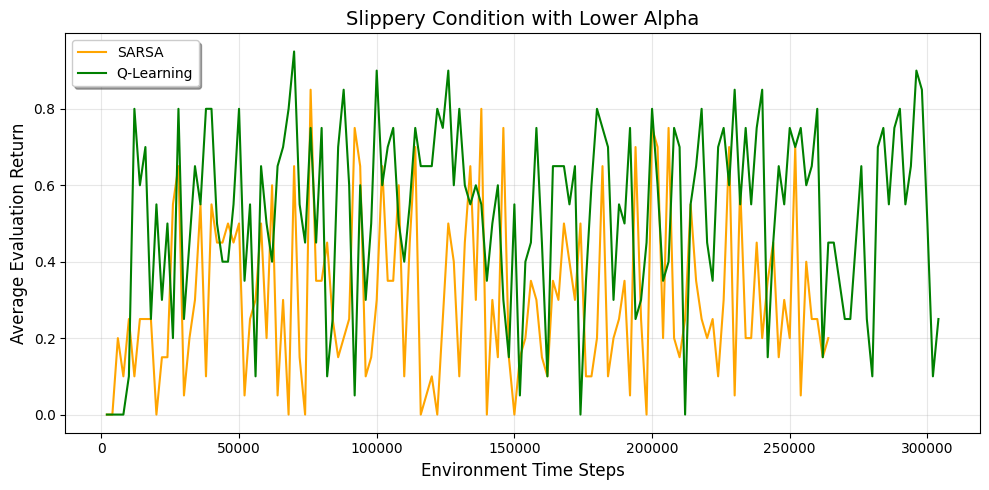

In [70]:
fig, ax = plt.subplots(1, 1, figsize=(10, 5))

ax.plot(sarsa_time_steps_slippery_la, sarsa_eval_returns_slippery_la, label='SARSA', color='orange')
ax.plot(ql_time_steps_slippery_la, ql_eval_returns_slippery_la, label='Q-Learning', color='green')

ax.set_title("Slippery Condition with Lower Alpha", fontsize=14)
ax.set_xlabel("Environment Time Steps", fontsize=12)
ax.set_ylabel("Average Evaluation Return", fontsize=12)
ax.legend(shadow=True, fancybox=True)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Plot Policy of Each Trained Agent

## Create a function to plot the policy of each agent on the "Frozen Lake" Board

### Function from Homework 1:

In [59]:
def plot_policy(policy, map):

  # Define shape of frozen lake
  shape = (4,4)

  # Correspond each action taken by the policy to an arrow
  action_symbol= {
    0 : '←',
    1 : '↓',
    2 : '→',
    3 : '↑'
  }
  symbols = np.array([action_symbol[action] for action in policy]).reshape(shape)

  # Create 4x4 plot
  fig, ax = plt.subplots(figsize=(5,5))
  ax.set_xticks(np.arange(shape[1]+1))
  ax.set_yticks(np.arange(shape[0]+1))
  ax.grid(True)

  # Add color to each square on the map
  # Use map defined at beginning of MDP
  # Need to convert bytes to strings
  for i in range(shape[0]):
    for j in range(shape[1]):
      tile = map[i][j].decode() if isinstance(map[i][j], bytes) else map[i][j]

      if tile == 'H':
        color = "gray"
      elif tile == 'S':
        color = "green"
      elif tile == 'G':
        color = "gold"
      elif tile == 'F':
        color = "white"

      # Draw square
      ax.add_patch(plt.Rectangle((j, i), 1, 1, facecolor=color, edgecolor='black'))

      # Add tile label
      ax.text(j + 0.5, i + 0.3, tile, ha='center', va='center', fontsize=12, weight='bold')

      # Add policy arrow
      if tile not in ['H','G']:
        ax.text(j+0.5, i+0.7, symbols[i,j], ha='center', va='center', fontsize=14, color="blue")

  # Format plot
  ax.set_xlim(0, shape[1])
  ax.set_ylim(0, shape[0])
  ax.invert_yaxis()
  plt.show()

## Extract Policy of Each Trained Agent

### Create a function to turn dictionary into array

Policy is in the form of a dictionary currently

In [60]:
def dict_to_array(policy_dict, env):

    n_states = env.observation_space.n
    policy_array = np.zeros(n_states, dtype=int)

    for s, a in policy_dict.items():
        policy_array[s] = int(a)

    return policy_array

### Non-Slippery Condition

Without Epsilon Decay:

In [61]:
# Monte Carlo
pi_mc_noslip = dict_to_array(mc_noslip[1], env_noslip)

# SARSA
pi_sarsa_noslip = dict_to_array(sarsa_noslip[1], env_noslip)

# Q-Learning
pi_ql_noslip = dict_to_array(q_learning_noslip[1], env_noslip)

With Epsilon Decay:

In [62]:
# Monte Carlo
pi_mc_noslip_decay = dict_to_array(mc_noslip_decay[1], env_noslip)

# SARSA
pi_sarsa_noslip_decay = dict_to_array(sarsa_noslip_decay[1], env_noslip)

# Q-Learning
pi_ql_noslip_decay = dict_to_array(q_learning_noslip_decay[1], env_noslip)

With Lower $\alpha$:

In [63]:
# SARSA
pi_sarsa_noslip_decay = dict_to_array(sarsa_noslip_la[1], env_noslip)

# Q-Learning
pi_ql_noslip_decay = dict_to_array(q_learning_noslip_la[1], env_noslip)

### Slippery Condition

Without Epsilon Decay:

In [64]:
# Monte Carlo
pi_mc_slippery = dict_to_array(mc_slippery[1], env_slippery)

# SARSA
pi_sarsa_slippery = dict_to_array(sarsa_slippery[1], env_slippery)

# Q-Learning
pi_ql_slippery = dict_to_array(q_learning_slippery[1], env_slippery)

With Epsilon Decay:

In [65]:
# Monte Carlo
pi_mc_slippery_decay = dict_to_array(mc_slippery_decay[1], env_slippery)

# SARSA
pi_sarsa_slippery_decay = dict_to_array(sarsa_slippery_decay[1], env_slippery)

# Q-Learning
pi_ql_slippery_decay = dict_to_array(q_learning_slippery_decay[1], env_slippery)

With Lower $\alpha$:

In [66]:
# SARSA
pi_sarsa_slippery_decay = dict_to_array(sarsa_slippery_la[1], env_slippery)

# Q-Learning
pi_ql_slippery_decay = dict_to_array(q_learning_slippery_la[1], env_slippery)

# Plot Policies

## Monte Carlo Policies

Non-Slippery Condition


/usr/local/lib/python3.12/dist-packages/gymnasium/core.py:311: UserWarning: WARN: env.desc to get variables from other wrappers is deprecated and will be removed in v1.0, to get this variable you can do `env.unwrapped.desc` for environment variables or `env.get_wrapper_attr('desc')` that will search the reminding wrappers.
  logger.warn(


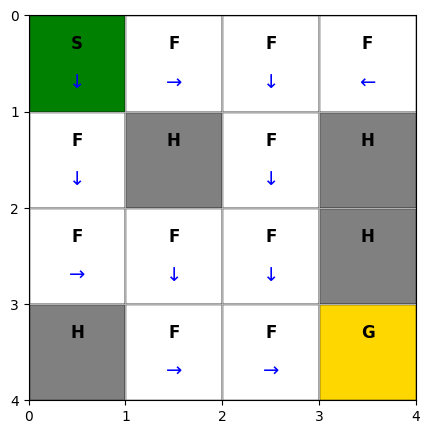

Non-Slippery Condition with Epsilon Decay


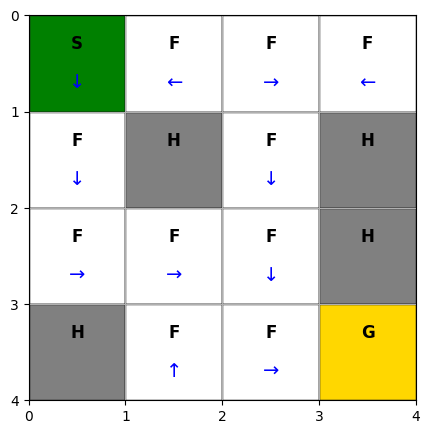

Slippery Condition


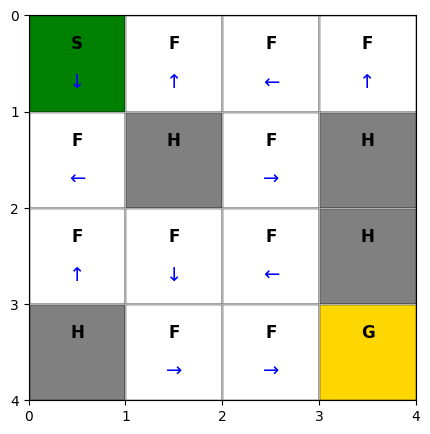

Slippery Condition with Epsilon Decay


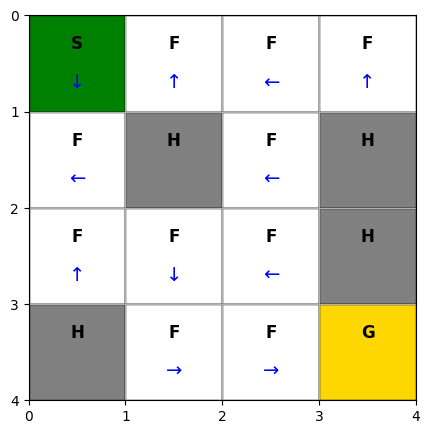

In [67]:
print("Non-Slippery Condition")
plot_policy(pi_mc_noslip, env_noslip.desc)

print("Non-Slippery Condition with Epsilon Decay")
plot_policy(pi_mc_noslip_decay, env_noslip.desc)

print("Slippery Condition")
plot_policy(pi_mc_slippery, env_slippery.desc)

print("Slippery Condition with Epsilon Decay")
plot_policy(pi_mc_slippery_decay, env_slippery.desc)

## SARSA Policies

In [68]:
print("Non-Slippery Condition")
plot_policy(pi_sarsa_noslip, env_noslip.desc)

print("Non-Slippery Condition with Epsilon Decay")
plot_policy(pi_sarsa_noslip_decay, env_noslip.desc)

print("\Non-Slippery Condition with lower alpha")
plot_policy(pi_sarsa_noslip_decay, env_noslip.desc)

print("Slippery Condition")
plot_policy(pi_sarsa_slippery, env_slippery.desc)

print("Slippery Condition with Epsilon Decay")
plot_policy(pi_sarsa_slippery_decay, env_slippery.desc)

print("Slippery Condition with lower alpha")
plot_policy(pi_sarsa_slippery_decay, env_slippery.desc)

SyntaxError: (unicode error) 'unicodeescape' codec can't decode bytes in position 0-1: malformed \N character escape (ipython-input-906031938.py, line 7)

## Q-Learning Policies

Non-Slippery Condition


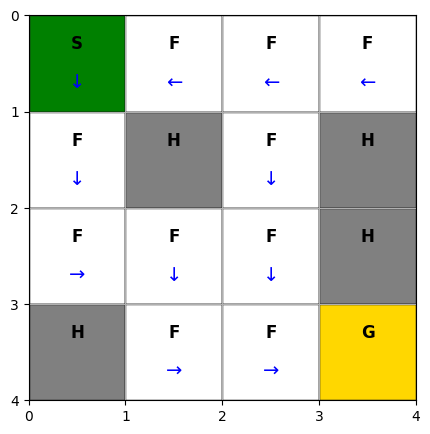

Non-Slippery Condition with Epsilon Decay


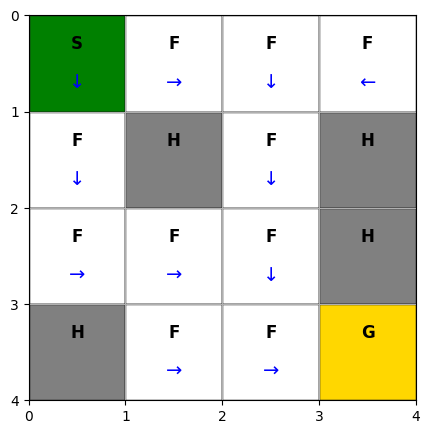

Non-Slippery Condition with lower alpha


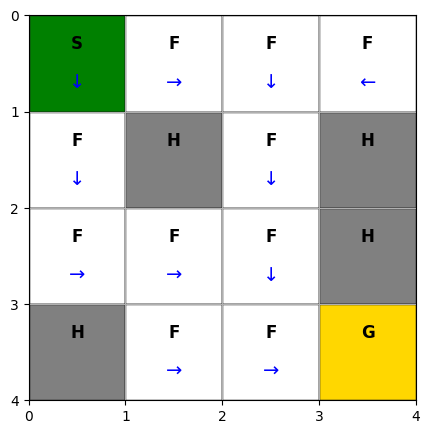

Slippery Condition


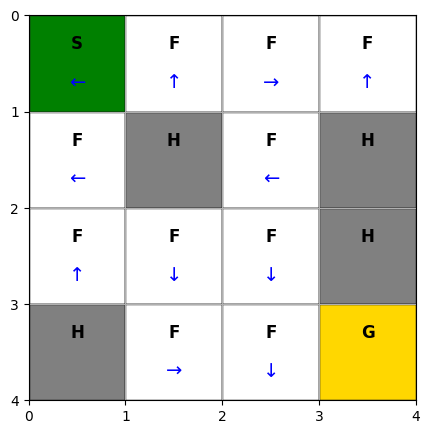

Slippery Condition with Epsilon Decay


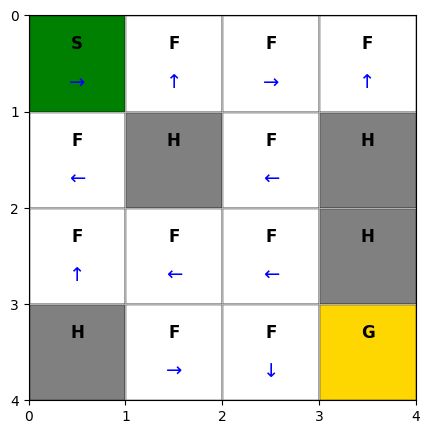

Slippery Condition with lower alpha


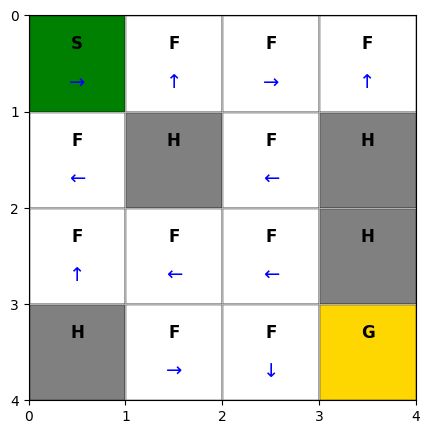

In [69]:
print("Non-Slippery Condition")
plot_policy(pi_ql_noslip, env_noslip.desc)

print("Non-Slippery Condition with Epsilon Decay")
plot_policy(pi_ql_noslip_decay, env_noslip.desc)

print("Non-Slippery Condition with lower alpha")
plot_policy(pi_ql_noslip_decay, env_noslip.desc)

print("Slippery Condition")
plot_policy(pi_ql_slippery, env_slippery.desc)

print("Slippery Condition with Epsilon Decay")
plot_policy(pi_ql_slippery_decay, env_slippery.desc)

print("Slippery Condition with lower alpha")
plot_policy(pi_ql_slippery_decay, env_slippery.desc)